In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [4]:
df = pd.read_csv("ecommerce.csv")

In [5]:
df.head()

,OrderID,Product,UnitPrice,Quantity,City,Customer
0,1001,Laptop,55000.0,1.0,Chennai,Ravi
1,1002,Mobile Phone,25000.0,2.0,Bengaluru,Priya
2,1003,Headphones,2500.0,3.0,Hyderabad,Arun
3,1004,Keyboard,1500.0,2.0,Chennai,Sita
4,1005,Monitor,12000.0,1.0,Mumbai,Kiran


In [6]:
df.shape

(21, 6)

In [7]:
df.columns

Index(['OrderID', 'Product', 'UnitPrice', 'Quantity', 'City', 'Customer'],
      dtype='str')

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   OrderID    21 non-null     int64  
 1   Product    21 non-null     str    
 2   UnitPrice  20 non-null     float64
 3   Quantity   20 non-null     float64
 4   City       20 non-null     str    
 5   Customer   20 non-null     str    
dtypes: float64(2), int64(1), str(3)
memory usage: 1.1 KB


In [9]:
df.isnull().sum()

OrderID      0
Product      0
UnitPrice    1
Quantity     1
City         1
Customer     1
dtype: int64

In [10]:
df.describe()

,OrderID,UnitPrice,Quantity
count,21.000000,20.000000,20.000000
mean,1010.142857,16790.000000,1.750000
std,5.994045,17997.160595,0.850696
min,1001.000000,800.000000,1.000000
25%,1005.000000,4000.000000,1.000000
50%,1010.000000,10500.000000,2.000000
75%,1015.000000,19750.000000,2.000000
max,1020.000000,55000.000000,4.000000


In [11]:
df[df.duplicated()]

,OrderID,Product,UnitPrice,Quantity,City,Customer
15,1003,Headphones,2500.0,3.0,Hyderabad,Arun


In [12]:
df.duplicated().sum()

np.int64(1)

In [14]:
df_clean = df.drop_duplicates()
df_clean.shape

(20, 6)

In [15]:
df_clean.isnull().sum()

OrderID      0
Product      0
UnitPrice    1
Quantity     1
City         1
Customer     1
dtype: int64

In [16]:
df_clean["City"] = df_clean["City"].fillna("Unknown")
df_clean["Customer"] = df_clean["Customer"].fillna("Unknown")

In [17]:
df_clean.isnull().sum()

OrderID      0
Product      0
UnitPrice    1
Quantity     1
City         0
Customer     0
dtype: int64

In [18]:
df_clean["Revenue"] = (
    df_clean["UnitPrice"] * df_clean["Quantity"]
)

In [19]:
df_clean[["Product", "UnitPrice", "Quantity", "Revenue"]]

,Product,UnitPrice,Quantity,Revenue
0,Laptop,55000.0,1.0,55000.0
1,Mobile Phone,25000.0,2.0,50000.0
2,Headphones,2500.0,3.0,7500.0
3,Keyboard,1500.0,2.0,3000.0
4,Monitor,12000.0,1.0,12000.0
5,Laptop,55000.0,1.0,55000.0
6,Smart Watch,8000.0,2.0,16000.0
7,Tablet,18000.0,1.0,18000.0
8,Mouse,800.0,4.0,3200.0
9,Gaming Chair,15000.0,1.0,15000.0


In [20]:
df_clean["Revenue"].sum()

np.float64(423700.0)

In [21]:
df_clean[df_clean["Revenue"].isnull()]

,OrderID,Product,UnitPrice,Quantity,City,Customer,Revenue
17,1017,Smart Watch,NaN,1.0,Chennai,Rahul,NaN
19,1019,Keyboard,1500.0,NaN,Mumbai,Vijay,NaN


In [22]:
product_sales = df_clean.groupby("Product")["Revenue"].sum()

print(product_sales.sort_values(ascending=False))

Product
Laptop                165000.0
Mobile Phone           75000.0
Tablet                 54000.0
Monitor                36000.0
Printer                27000.0
Smart Watch            16000.0
Gaming Chair           15000.0
External Hard Disk     13000.0
Webcam                  9000.0
Headphones              7500.0
Mouse                   3200.0
Keyboard                3000.0
Name: Revenue, dtype: float64


In [23]:
product_sales = df_clean.groupby("Product")["Revenue"].sum()

print(product_sales.sort_values(ascending=False))

Product
Laptop                165000.0
Mobile Phone           75000.0
Tablet                 54000.0
Monitor                36000.0
Printer                27000.0
Smart Watch            16000.0
Gaming Chair           15000.0
External Hard Disk     13000.0
Webcam                  9000.0
Headphones              7500.0
Mouse                   3200.0
Keyboard                3000.0
Name: Revenue, dtype: float64


In [24]:
city_sales = df_clean.groupby("City")["Revenue"].sum()

print(city_sales.sort_values(ascending=False))

City
Chennai      156000.0
Bengaluru    106000.0
Hyderabad    101500.0
Unknown       36000.0
Mumbai        24200.0
Name: Revenue, dtype: float64


In [25]:
quantity_sales = df_clean.groupby("Product")["Quantity"].sum()

print(quantity_sales.sort_values(ascending=False))

Product
Mouse                 4.0
Headphones            3.0
Laptop                3.0
Mobile Phone          3.0
Printer               3.0
Smart Watch           3.0
Tablet                3.0
Monitor               3.0
External Hard Disk    2.0
Keyboard              2.0
Webcam                2.0
Gaming Chair          1.0
Name: Quantity, dtype: float64


In [26]:
df_clean["Revenue"].mean()

np.float64(23538.88888888889)

In [27]:
df_clean["Revenue"].median()

np.float64(17000.0)

In [28]:
df_clean["Revenue"].min()

np.float64(3000.0)

In [29]:
df_clean["Revenue"].max()

np.float64(55000.0)

In [30]:
df_clean["Revenue"].std()

np.float64(18435.998637221528)

In [31]:
df_clean["Revenue"].describe()

count       18.000000
mean     23538.888889
std      18435.998637
min       3000.000000
25%       9750.000000
50%      17000.000000
75%      33250.000000
max      55000.000000
Name: Revenue, dtype: float64

In [32]:
high_value_orders = df_clean[df_clean["Revenue"] > 20000]

high_value_orders

,OrderID,Product,UnitPrice,Quantity,City,Customer,Revenue
0,1001,Laptop,55000.0,1.0,Chennai,Ravi,55000.0
1,1002,Mobile Phone,25000.0,2.0,Bengaluru,Priya,50000.0
5,1006,Laptop,55000.0,1.0,Hyderabad,Anil,55000.0
11,1012,Mobile Phone,25000.0,1.0,Bengaluru,Ravi,25000.0
13,1014,Laptop,55000.0,1.0,Chennai,Priya,55000.0
14,1015,Monitor,12000.0,2.0,Hyderabad,Kiran,24000.0
18,1018,Tablet,18000.0,2.0,Unknown,Divya,36000.0


In [33]:
df_clean["Price_After_10_Percent"] = df_clean["UnitPrice"] * 1.10

In [34]:
df_clean[["Product", "UnitPrice", "Price_After_10_Percent"]]

,Product,UnitPrice,Price_After_10_Percent
0,Laptop,55000.0,60500.0
1,Mobile Phone,25000.0,27500.0
2,Headphones,2500.0,2750.0
3,Keyboard,1500.0,1650.0
4,Monitor,12000.0,13200.0
5,Laptop,55000.0,60500.0
6,Smart Watch,8000.0,8800.0
7,Tablet,18000.0,19800.0
8,Mouse,800.0,880.0
9,Gaming Chair,15000.0,16500.0


In [35]:
df_clean["Price_After_10_Percent"].sum()

np.float64(366630.0)

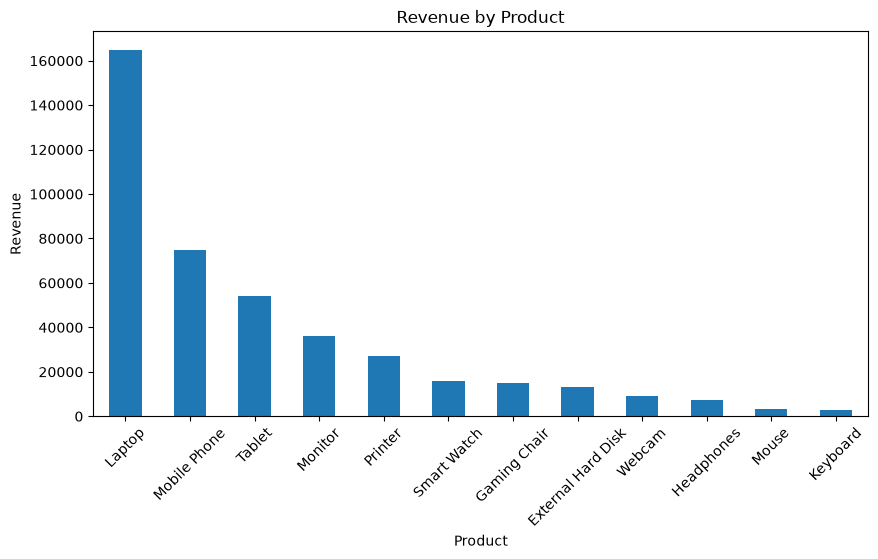

In [36]:
product_sales = df_clean.groupby("Product")["Revenue"].sum().sort_values(ascending=False)

product_sales.plot(kind="bar", figsize=(10, 5))

plt.title("Revenue by Product")
plt.xlabel("Product")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.show()

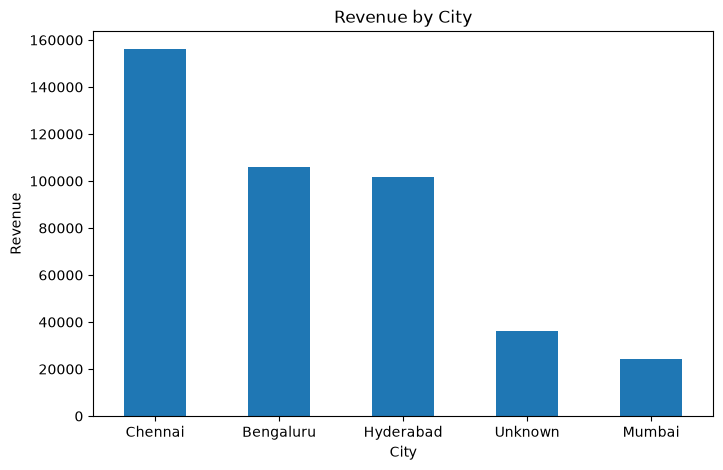

In [37]:
city_sales = df_clean.groupby("City")["Revenue"].sum().sort_values(ascending=False)

city_sales.plot(kind="bar", figsize=(8, 5))

plt.title("Revenue by City")
plt.xlabel("City")
plt.ylabel("Revenue")
plt.xticks(rotation=0)
plt.show()

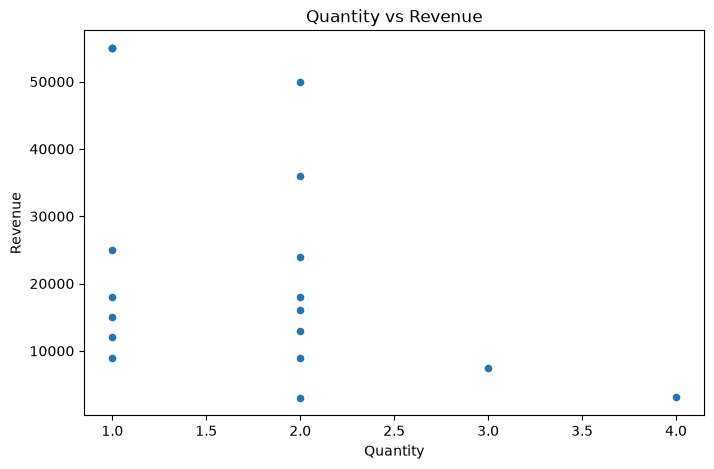

In [38]:
df_clean.plot(
    x="Quantity",
    y="Revenue",
    kind="scatter",
    figsize=(8, 5)
)

plt.title("Quantity vs Revenue")
plt.xlabel("Quantity")
plt.ylabel("Revenue")
plt.show()

In [39]:
df_clean.to_csv("ecommerce_cleaned.csv", index=False)

In [40]:
product_sales.to_csv("product_sales.csv")

In [41]:
city_sales.to_csv("city_sales.csv")

In [42]:
pd.read_csv("ecommerce_cleaned.csv").head()

,OrderID,Product,UnitPrice,Quantity,City,Customer,Revenue,Price_After_10_Percent
0,1001,Laptop,55000.0,1.0,Chennai,Ravi,55000.0,60500.0
1,1002,Mobile Phone,25000.0,2.0,Bengaluru,Priya,50000.0,27500.0
2,1003,Headphones,2500.0,3.0,Hyderabad,Arun,7500.0,2750.0
3,1004,Keyboard,1500.0,2.0,Chennai,Sita,3000.0,1650.0
4,1005,Monitor,12000.0,1.0,Mumbai,Kiran,12000.0,13200.0
